# Bloch-wave analysis of a phononic crystal plate {far}`star`{far}`star`

```{admonition} Coauthors
:class: coauthors

This tour has been written in collaboration with:

**Felipe Rocha** (Université Gustave Eiffel, felipe.figueredo-rocha@u-pec.fr) https://felipefr.github.io/
```

```{admonition} Objectives
:class: objectives

This tour computes the dispersion diagram of in-plane elastic waves in a plate perforated by a periodic array of circular holes. Using Bloch's theorem, wave propagation in the infinite periodic medium reduces to a family of eigenvalue problems on a single unit cell, parametrized by the wave vector. We show how to formulate these problems with complex-valued forms in a standard (real) build of DOLFINx and how to identify a complete band gap.
$\newcommand{\bu}{\boldsymbol{u}}
\newcommand{\bv}{\boldsymbol{v}}
\newcommand{\bw}{\boldsymbol{w}}
\newcommand{\bk}{\boldsymbol{k}}
\newcommand{\bx}{\boldsymbol{x}}
\newcommand{\br}{\boldsymbol{r}}
\newcommand{\bq}{\boldsymbol{q}}
\newcommand{\be}{\boldsymbol{e}}
\newcommand{\bsig}{\boldsymbol{\sigma}}
\newcommand{\beps}{\boldsymbol{\varepsilon}}
\newcommand{\bI}{\boldsymbol{I}}
\newcommand{\dOm}{\,\text{d}\Omega}
\newcommand{\tr}{\operatorname{tr}}$
```

```{image} bloch_waves.png
:width: 600px
:align: center
```

```{attention}
This tour requires DOLFINx v0.11 and the `dolfinx_mpc` add-on package (v0.11) to define periodic constraints. It runs with the standard real-valued PETSc build: complex-valued forms are assembled into `scipy` matrices, so no complex PETSc build is needed. The eigenvalue problems are solved with `scipy`, which restricts this implementation to serial runs.
```

```{admonition} Download sources
:class: download

* {Download}`Python script<./bloch_waves.py>`
* {Download}`Jupyter notebook<./bloch_waves.ipynb>`
```

```{seealso}
Periodic boundary conditions are also used in [](/tours/homogenization/periodic_elasticity/periodic_elasticity.md). Eigenvalue problems for structures are discussed in [](/intro/plates/plates.md) and [](/tours/eigenvalue_problems/buckling_3d_solid/buckling_3d_solid.md).
```

## Waves in periodic media

### Bloch's theorem

We consider a linear elastic medium which is periodic with respect to a lattice of vectors $\br = n_1L\be_1 + n_2L\be_2$, $(n_1, n_2) \in \mathbb{Z}^2$. The square unit cell $\Omega = [0, L]^2$ contains four circular holes with traction-free boundaries. Time-harmonic waves $\bu(\bx, t) = \bw(\bx)e^{-i\omega t}$ satisfy:

$$
\operatorname{div}\bsig(\bw) + \rho\omega^2\bw = 0, \qquad \bsig(\bw) = \lambda\tr(\beps(\bw))\bI + 2\mu\beps(\bw)
$$

where we assume plane strain conditions. Bloch's theorem {cite:p}`brillouin1953wave` states that the eigenmodes of a periodic medium can be sought as Bloch waves, i.e. plane waves modulated by a periodic function:

```{math}
:label: bloch-condition

\bw(\bx + \br) = \bw(\bx)e^{i\bk\cdot\br} \quad \text{for all lattice vectors } \br
```

where $\bk$ is the wave vector. Since $e^{i\bq\cdot\br} = 1$ for any vector $\bq = \dfrac{2\pi}{L}(m_1\be_1 + m_2\be_2)$ of the reciprocal lattice, the wave vectors $\bk$ and $\bk + \bq$ describe the same Bloch wave. It is therefore sufficient to consider $\bk$ in the first Brillouin zone $[-\pi/L, \pi/L]^2$. Using in addition the symmetries of the unit cell, $\bk$ can be further restricted to the *irreducible Brillouin zone*, the triangle $\Gamma\text{X}\text{M}$ shown below {cite:p}`hussein2014dynamics`.

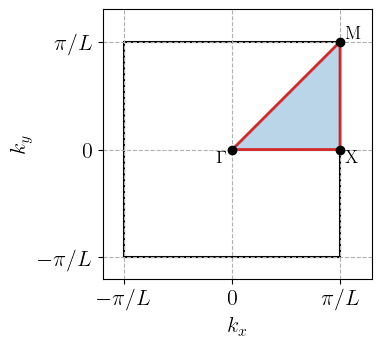

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.add_patch(Polygon([[-1, -1], [1, -1], [1, 1], [-1, 1]], fill=False, lw=1.5))
ax.add_patch(Polygon([[0, 0], [1, 0], [1, 1]], color="C0", alpha=0.3))
ax.plot([0, 1, 1, 0], [0, 0, 1, 0], "-C3", lw=2)
for label, (x, y), offset in zip(
    [r"$\Gamma$", "X", "M"],
    [(0, 0), (1, 0), (1, 1)],
    [(-0.15, -0.12), (0.05, -0.12), (0.05, 0.03)],
):
    ax.plot(x, y, "ok")
    ax.text(x + offset[0], y + offset[1], label, fontsize=13)
ax.set_xticks([-1, 0, 1], [r"$-\pi/L$", "0", r"$\pi/L$"])
ax.set_yticks([-1, 0, 1], [r"$-\pi/L$", "0", r"$\pi/L$"])
ax.set_xlabel(r"$k_x$")
ax.set_ylabel(r"$k_y$")
ax.set_aspect("equal")
ax.set_xlim(-1.2, 1.3)
ax.set_ylim(-1.2, 1.3)
plt.show()

For each wave vector $\bk$ along the contour $\Gamma\to\text{X}\to\text{M}\to\Gamma$, we compute the frequencies $\omega_n(\bk)$ of the Bloch waves. The resulting curves form the *dispersion diagram*, or band structure. A frequency range in which no band exists for any $\bk$ is a *complete band gap*: no wave can propagate in the medium at these frequencies, whatever its direction.

```{note}
Band extrema are usually located on the contour of the irreducible Brillouin zone, but this is not guaranteed in general. A safer check of a band gap consists in sampling the whole irreducible zone.
```

### Weak form with a periodic unknown

A direct implementation of {eq}`bloch-condition` would require complex-valued periodicity constraints depending on $\bk$. Instead, we write the Bloch wave as $\bw(\bx) = \widehat{\bw}(\bx)e^{i\bk\cdot\bx}$, where $\widehat{\bw}$ is $\Omega$-periodic. Indeed, $\bw(\bx + \br) = \widehat{\bw}(\bx)e^{i\bk\cdot\bx}e^{i\bk\cdot\br} = \bw(\bx)e^{i\bk\cdot\br}$. The periodicity constraint is then the same for all $\bk$, and the wave vector appears in the gradient:

$$
\nabla\bw = e^{i\bk\cdot\bx}\left(\nabla\widehat{\bw} + i\,\widehat{\bw}\otimes\bk\right) = e^{i\bk\cdot\bx}\,\nabla_{\bk}\widehat{\bw}
$$

where $\nabla_{\bk}\widehat{\bw} = \nabla\widehat{\bw} + i\,\widehat{\bw}\otimes\bk$ is the *Bloch gradient*. Since the phase factors $e^{i\bk\cdot\bx}$ cancel in the Hermitian products of the weak form, the problem reads:

> Find $\widehat{\bw} \neq 0$ periodic and $\omega$ such that:
> ```{math}
> :label: bloch-eigenproblem
>
>\int_\Omega \bsig(\nabla^\text{s}_{\bk}\widehat{\bw}) : \overline{\nabla^\text{s}_{\bk}\bv} \dOm = \omega^2\int_\Omega \rho\, \widehat{\bw}\cdot\overline{\bv} \dOm \quad \forall \bv \text{ periodic}
> ```

where $\nabla^\text{s}_{\bk}$ is the symmetric part of the Bloch gradient and the overline denotes complex conjugation. After discretization, we obtain a generalized eigenvalue problem $[\mathbf{K}(\bk)]\{\widehat{w}\} = \omega^2[\mathbf{M}]\{\widehat{w}\}$, where $[\mathbf{K}(\bk)]$ is Hermitian positive semi-definite and $[\mathbf{M}]$ is real symmetric positive definite and independent of $\bk$. The eigenvalues $\omega^2$ are therefore real and non-negative.

## Implementation

### Unit cell and periodic mesh

The unit cell has size $L=1$ and contains four holes of radius $R=0.2$ centered at $(L/4, L/4)$, $(3L/4, L/4)$, $(3L/4, 3L/4)$ and $(L/4, 3L/4)$. The solid has Young's modulus $E=300$, Poisson's ratio $\nu=0.3$ and density $\rho=1$, in arbitrary consistent units. Frequencies are reported in normalized form $\bar\omega = \omega L/(2\pi c_T)$, where $c_T = \sqrt{\mu/\rho}$ is the shear wave velocity.

In [9]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import gmsh
import ufl
from mpi4py import MPI
from dolfinx import fem, io, plot
import dolfinx_mpc

comm = MPI.COMM_WORLD
assert comm.size == 1, "This tour relies on scipy eigensolvers and runs in serial only."
model_rank = 0
gdim = 2

L = 1.0  # unit cell size
R = 0.2  # hole radius
hole_centers = [(0.25, 0.25), (0.75, 0.25), (0.75, 0.75), (0.25, 0.75)]
hsize = 0.05  # mesh size

E, nu, rho = 300.0, 0.3, 1.0
mu = E / 2 / (1 + nu)
lmbda = E * nu / (1 + nu) / (1 - 2 * nu)  # plane strain
c_T = np.sqrt(mu / rho)  # shear wave velocity

The unit cell is generated with the `gmsh` Python API. Since the Bloch condition relates opposite edges of the cell, we use `setPeriodic` so that the meshes of opposite edges are identical.

In [10]:
gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 0)  # to disable meshing info
if comm.rank == model_rank:
    occ = gmsh.model.occ
    cell = occ.addRectangle(0, 0, 0, L, L)
    holes = [occ.addDisk(x, y, 0, R, R) for x, y in hole_centers]
    occ.cut([(gdim, cell)], [(gdim, hole) for hole in holes])
    occ.synchronize()
    surfaces = [tag for _, tag in gmsh.model.getEntities(gdim)]
    gmsh.model.addPhysicalGroup(gdim, surfaces, 1, name="Solid")

    eps = 1e-6 * L

    def edges_in_box(xmin, ymin, xmax, ymax):
        box = (xmin - eps, ymin - eps, -eps, xmax + eps, ymax + eps, eps)
        return [
            tag for _, tag in gmsh.model.getEntitiesInBoundingBox(*box, dim=gdim - 1)
        ]

    # right edge is the image of the left one, top edge the image of the bottom one
    for slave, master, shift in [
        (edges_in_box(L, 0, L, L), edges_in_box(0, 0, 0, L), (L, 0)),
        (edges_in_box(0, L, L, L), edges_in_box(0, 0, L, 0), (0, L)),
    ]:
        translation = np.eye(4)
        translation[:2, 3] = shift
        gmsh.model.mesh.setPeriodic(
            gdim - 1, slave, master, translation.flatten().tolist()
        )

    gmsh.option.setNumber("Mesh.MeshSizeMin", hsize)
    gmsh.option.setNumber("Mesh.MeshSizeMax", hsize)
    gmsh.model.mesh.generate(gdim)

domain = io.gmsh.model_to_mesh(gmsh.model, comm, model_rank, gdim=gdim).mesh
gmsh.finalize()

```{note}
The four holes are identical and arranged with period $L/2$, so the cell contains $2\times 2$ periods of a simpler lattice with one hole per cell. The dispersion diagram computed below is the exact one for the chosen cell, but it contains *folded* bands: each band of the one-hole lattice appears together with copies shifted by reciprocal vectors $2\pi/L$.
```

### Periodic constraint and reduction matrix

The periodic unknown $\widehat{\bw}$ is constrained with a `MultiPointConstraint` from `dolfinx_mpc`. Degrees of freedom on the right and top edges (the *slaves*) are expressed in terms of those on the left and bottom edges (the *masters*) by a single map which subtracts $L$ from every coordinate equal to $L$. In particular, the three corners $(L,0)$, $(0,L)$ and $(L,L)$ are all mapped directly onto the origin, so that no slave is constrained twice, see [](/tours/homogenization/periodic_elasticity/periodic_elasticity.md). Contrary to static homogenization problems, we do not fix any degree of freedom: rigid translations are genuine zero-frequency Bloch waves at $\bk=0$.

The periodic constraint does not depend on $\bk$ and is real-valued. We store it as a sparse matrix $[\mathbf{P}]$ such that the full vector of degrees of freedom reads $\{\widehat{w}\} = [\mathbf{P}]\{\widehat{w}_r\}$ in terms of the reduced vector $\{\widehat{w}_r\}$ of non-slave degrees of freedom. The constrained matrices are then $[\mathbf{P}]^\text{T}[\mathbf{K}][\mathbf{P}]$ and $[\mathbf{P}]^\text{T}[\mathbf{M}][\mathbf{P}]$.

```{attention}
Here we use a real PETSc build which requires us to build explicitly `P`. With a complex PETSc build, `dolfinx_mpc.assemble_matrix` does the reduction itself. One can then use  and SLEPc direclty and run the demo in parallel, avoiding any explicit construction of `P`.
```

In [11]:
def periodic_reduction_matrix(V, L, tol=1e-8):
    """Matrix P such that u = P u_r, where u_r gathers the non-slave dofs."""

    def slave_edges(x):
        return np.isclose(x[0], L, atol=tol) | np.isclose(x[1], L, atol=tol)

    def periodic_map(x):
        y = x.copy()
        y[np.isclose(x, L, atol=tol)] -= L
        return y

    mpc = dolfinx_mpc.MultiPointConstraint(V)
    mpc.create_periodic_constraint_geometrical(V, slave_edges, periodic_map, [])
    mpc.finalize()

    num_dofs = V.dofmap.index_map.size_local * V.dofmap.index_map_bs
    slaves = mpc.slaves
    retained = np.setdiff1d(np.arange(num_dofs), slaves)
    column = np.full(num_dofs, -1)
    column[retained] = np.arange(len(retained))

    rows, cols, vals = [retained], [column[retained]], [np.ones(len(retained))]
    coefficients, offsets = mpc.coefficients()
    for s in slaves:  # master lists are indexed by dof number
        masters = mpc.masters.links(s)
        coeffs = coefficients[offsets[s] : offsets[s + 1]]
        nonzero = np.abs(coeffs) > 1e-12
        rows.append(np.full(np.sum(nonzero), s))
        cols.append(column[masters[nonzero]])
        vals.append(coeffs[nonzero])
    rows, cols, vals = map(np.concatenate, (rows, cols, vals))
    assert np.all(cols >= 0), "A master dof is also a slave dof."
    return sp.csr_matrix((vals, (rows, cols)), shape=(num_dofs, len(retained)))

### Complex-valued forms in a real build

DOLFINx compiles and assembles forms for several scalar types, independently of the scalar type of the PETSc installation. We therefore assemble the complex-valued forms of {eq}`bloch-eigenproblem` with `dtype=np.complex128` and convert them to `scipy` sparse matrices. The displacement is discretized with quadratic Lagrange elements. The wave vector is a complex-valued `fem.Constant`, updated for each point of the dispersion diagram, so that the forms are compiled only once. The mass matrix does not depend on $\bk$ and is assembled once.

The Bloch gradient is written in index notation. Note that `ufl.outer(a, b)` conjugates its first argument in complex mode, while `ufl.inner(a, b)` conjugates its second argument: the test function then appears conjugated, as required for a sesquilinear form.

The generalized eigenvalue problem is solved with `scipy.sparse.linalg.eigsh` in shift-and-invert mode. Since $[\mathbf{K}(\bk)]$ is singular at $\bk = 0$ (rigid translations), we use a small negative shift $\sigma$ so that $[\mathbf{K}] - \sigma[\mathbf{M}]$ is always positive definite.

In [12]:
class BlochEigenproblem:
    """Bloch eigenvalue problem on a periodic unit cell [0, L]^2."""

    def __init__(self, domain, degree=2):
        self.V = fem.functionspace(domain, ("Lagrange", degree, (gdim,)))
        self.P = periodic_reduction_matrix(self.V, L)
        self.k = fem.Constant(domain, np.zeros(gdim, dtype=np.complex128))

        w = ufl.TrialFunction(self.V)
        v = ufl.TestFunction(self.V)
        i, j = ufl.indices(2)

        def bloch_strain(u):
            grad_k = ufl.grad(u) + 1j * ufl.as_tensor(u[i] * self.k[j], (i, j))
            return ufl.sym(grad_k)

        def sigma(eps):
            return lmbda * ufl.tr(eps) * ufl.Identity(gdim) + 2 * mu * eps

        self.stiffness = fem.form(
            ufl.inner(sigma(bloch_strain(w)), bloch_strain(v)) * ufl.dx,
            dtype=np.complex128,
        )
        mass = fem.form(rho * ufl.inner(w, v) * ufl.dx, dtype=np.complex128)
        M = fem.assemble_matrix(mass).to_scipy()
        self.M = (self.P.T @ M @ self.P).tocsc()
        self.shift = -1e-3 * (2 * np.pi * c_T / L) ** 2

    def solve(self, k, num_eig, return_modes=False):
        """Return the normalized frequencies (and Bloch modes) for wave vector k."""
        self.k.value[:] = k
        K = fem.assemble_matrix(self.stiffness).to_scipy()
        K = (self.P.T @ K @ self.P).tocsc()
        eigvals, eigvecs = spla.eigsh(
            K, k=num_eig, M=self.M, sigma=self.shift, which="LM"
        )
        order = np.argsort(eigvals.real)
        omega = np.sqrt(np.maximum(eigvals.real[order], 0.0))
        Omega = omega * L / (2 * np.pi * c_T)
        if return_modes:
            return Omega, self.P @ eigvecs[:, order]
        return Omega

### Dispersion diagram

We define the wave vectors along the contour $\Gamma\to\text{X}\to\text{M}\to\Gamma$, with $\text{X} = (\pi/L, 0)$ and $\text{M} = (\pi/L, \pi/L)$, and the corresponding abscissa for plotting.

In [13]:
def k_path(num_per_segment):
    Gamma = np.array([0.0, 0.0])
    X = np.array([np.pi / L, 0.0])
    M = np.array([np.pi / L, np.pi / L])
    t = np.linspace(0, 1, num_per_segment, endpoint=False)[:, None]
    points = np.vstack(
        [Gamma + t * (X - Gamma), X + t * (M - X), M + t * (Gamma - M), Gamma[None, :]]
    )
    abscissa = np.concatenate(
        [[0.0], np.cumsum(np.linalg.norm(np.diff(points, axis=0), axis=1))]
    )
    ticks = abscissa[[0, num_per_segment, 2 * num_per_segment, -1]]
    return points, abscissa, ticks


k_points, s, ticks = k_path(num_per_segment=30)

We then solve the eigenvalue problem for each wave vector.

In [14]:
problem = BlochEigenproblem(domain, degree=2)
num_bands = 20
Omega = np.array([problem.solve(k, num_bands) for k in k_points])

The band index $n$ is defined by sorting the frequencies at each wave vector. A complete band gap exists between bands $n$ and $n+1$ if the maximum of band $n$ along the contour is lower than the minimum of band $n+1$.

In [15]:
gaps = []
for n in range(num_bands - 1):
    lower, upper = Omega[:, n].max(), Omega[:, n + 1].min()
    if upper > lower:
        gaps.append((n, lower, upper))
        print(
            f"Complete band gap between bands {n + 1} and {n + 2}: "
            f"{lower:.3f} < Omega < {upper:.3f} "
            f"(gap-to-midgap ratio {2 * (upper - lower) / (upper + lower):.1%})"
        )

Complete band gap between bands 12 and 13: 1.375 < Omega < 1.572 (gap-to-midgap ratio 13.3%)


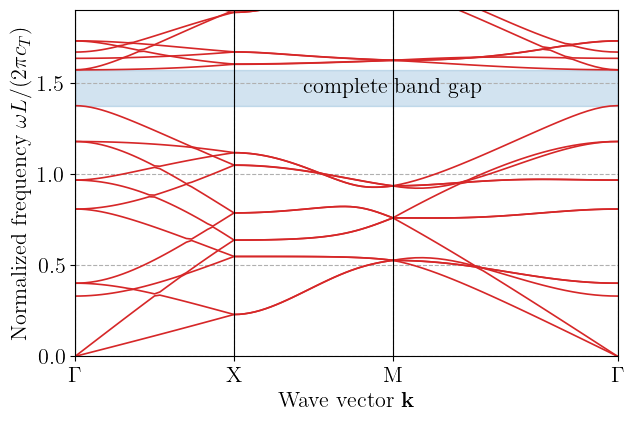

In [16]:
Omega_max = Omega[:, -1].min()
fig, ax = plt.subplots(figsize=(7, 4.5))
for n, lower, upper in gaps:
    ax.axhspan(lower, upper, color="C0", alpha=0.2)
for n in range(num_bands):
    ax.plot(s, Omega[:, n], "-C3", lw=1.2)
for t in ticks:
    ax.axvline(t, color="k", lw=0.8)
ax.set_xticks(ticks, [r"$\Gamma$", "X", "M", r"$\Gamma$"])
ax.set_xlim(ticks[0], ticks[-1])
ax.set_ylim(0, Omega_max)
ax.set_xlabel(r"Wave vector $\mathbf{k}$")
ax.set_ylabel(r"Normalized frequency $\omega L/(2\pi c_T)$")
ax.text(
    ticks[2],
    0.5 * (gaps[0][1] + gaps[0][2]),
    "complete band gap",
    ha="center",
    va="center",
)
plt.show()

The two acoustic bands start from zero frequency at $\Gamma$, with slopes given by the effective shear and pressure wave velocities of the porous plate. A complete band gap opens at higher frequencies, a typical feature of highly porous phononic crystals.

```{note}
Bands are drawn by connecting the sorted frequencies of successive wave vectors. Where two bands cross, the curves touch rather than cross, since sorting cannot identify individual modes. Following modes through crossings requires comparing eigenvectors at successive wave vectors.
```

### Bloch modes at the band gap edges

We finally plot the Bloch modes $\bw = \widehat{\bw}e^{i\bk\cdot\bx}$ at the lower and upper edges of the band gap, i.e. at the wave vectors where band $n$ reaches its maximum and band $n+1$ its minimum. Since eigenvectors are defined up to a complex factor, each mode is first multiplied by a phase factor making its largest component real, and we plot its real part.

In [17]:
n_gap = gaps[0][0]
edges = {
    "Lower gap edge": (n_gap, k_points[np.argmax(Omega[:, n_gap])]),
    "Upper gap edge": (n_gap + 1, k_points[np.argmin(Omega[:, n_gap + 1])]),
}
for title, (n, k) in edges.items():
    print(f"{title}: band {n + 1} at k = {np.round(k, 4)}")

Lower gap edge: band 12 at k = [0. 0.]
Upper gap edge: band 13 at k = [0. 0.]


Both edges are located at $\Gamma$, so that the corresponding modes are periodic. The lower edge is a single mode. The upper edge belongs to a pair of modes related by a $90°$ rotation, whose frequencies differ slightly because the unstructured mesh does not exactly preserve the symmetry of the cell; we plot one of them.

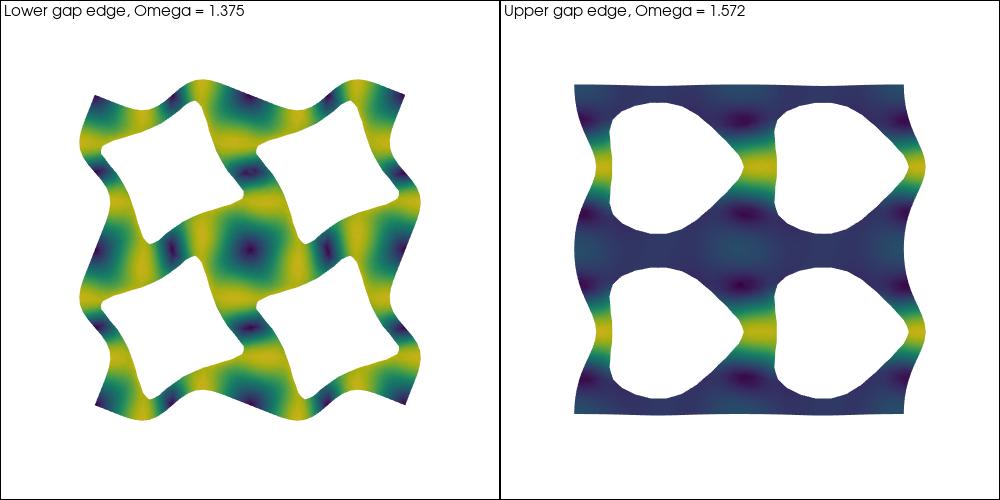

In [18]:
import pyvista

pyvista.set_jupyter_backend("static")

topology, cell_types, geometry = plot.vtk_mesh(problem.V)
plotter = pyvista.Plotter(shape=(1, 2), window_size=(1000, 500))
for col, (title, (n, k)) in enumerate(edges.items()):
    Omega_k, modes = problem.solve(k, num_bands, return_modes=True)
    w = modes[:, n].reshape(-1, gdim) * np.exp(1j * geometry[:, :2] @ k)[:, None]
    imax = np.argmax(np.abs(w))
    w = np.real(w * np.conj(w.flat[imax]) / np.abs(w.flat[imax]))

    grid = pyvista.UnstructuredGrid(topology, cell_types, geometry)
    grid.point_data["w"] = np.column_stack([w, np.zeros(len(w))])
    grid.point_data["|w|"] = np.linalg.norm(w, axis=1)
    scale = 0.05 * L / np.max(grid.point_data["|w|"])
    plotter.subplot(0, col)
    plotter.add_mesh(
        grid.warp_by_vector("w", factor=scale),
        scalars="|w|",
        cmap="viridis",
        show_scalar_bar=False,
    )
    plotter.add_text(f"{title}, Omega = {Omega_k[n]:.3f}", font_size=11)
    plotter.view_xy()
plotter.show()

## References

```{bibliography}
:filter: docname in docnames
```